# Qwen3-8B study workbench

Notebook-first study for `Qwen/Qwen3-8B`. This notebook never invokes an experiment runner: analysis calls only the reusable `src/` library. All model-specific outputs, including the Hugging Face cache/archive, are written below `Qwen3-8B_Results/`.

Run cells in order. M1 remains locked until M0 has written a passing report and testing-log entry.

In [1]:
from pathlib import Path
import csv
import json
import os
import platform
import random
import subprocess
from datetime import datetime, timezone

MODEL_KEY = 'qwen3_8b'
MODEL_ID = 'Qwen/Qwen3-8B'
DTYPE = 'bfloat16'
QUANTIZATION = 'none'
GROUP_SIZE = 128
SEEDS = {'python': 20260921, 'numpy': 20260921, 'torch': 20260921}
M0_PROMPTS = [
    {'id': 'm0_coding', 'category': 'coding', 'text': 'Implement Dijkstra in Rust using a binary heap.'},
    {'id': 'm0_knowledge', 'category': 'general_knowledge', 'text': 'What is the boiling point of water at sea level?'},
]

ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError('Open this root-level notebook from the SliceWeave workspace.')
    ROOT = ROOT.parent
NOTEBOOK_PATH = ROOT / 'notebooks' / 'qwen3_model_study.ipynb'
BUNDLE = ROOT / 'Qwen3-8B_Results'
RESULTS = BUNDLE / 'results'
MODEL_CACHE = BUNDLE / 'model_weights'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
assert BUNDLE.is_dir(), f'Missing prepared model bundle: {BUNDLE}'
assert not (BUNDLE / 'notebooks').exists() or not any((BUNDLE / 'notebooks').iterdir()), 'Use only the root-level notebooks folder for workbenches.'

# Keep every Hugging Face artifact and optional Xet cache inside this 8B bundle.
os.environ['HF_HOME'] = str(MODEL_CACHE / 'hf_home')
os.environ['HF_HUB_CACHE'] = str(MODEL_CACHE)
os.environ['HF_XET_CACHE'] = str(MODEL_CACHE / 'xet')
os.environ['TRANSFORMERS_CACHE'] = str(MODEL_CACHE)
for relative in ['logs', 'm0_exactness/csv', 'm1_oracle_sparsity/csv', 'm1_oracle_sparsity/plots']:
    (RESULTS / relative).mkdir(parents=True, exist_ok=True)
print({'model': MODEL_ID, 'bundle': str(BUNDLE), 'run_id': RUN_ID, 'notebook': str(NOTEBOOK_PATH)})

{'model': 'Qwen/Qwen3-8B', 'bundle': 'E:\\Project\\SliceWeave\\Qwen3-8B_Results', 'run_id': '20260921T100520Z', 'notebook': 'E:\\Project\\SliceWeave\\notebooks\\qwen3_model_study.ipynb'}


In [2]:
# Pre-M0 reproducibility record: resolve and pin the upstream revision before loading weights.
import sys
import numpy as np
import torch
import transformers
import accelerate
import huggingface_hub
from huggingface_hub import HfApi

random.seed(SEEDS['python'])
np.random.seed(SEEDS['numpy'])
torch.manual_seed(SEEDS['torch'])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEEDS['torch'])

MODEL_REVISION = HfApi().model_info(MODEL_ID).sha
try:
    git_commit = subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True).strip()
except Exception:
    git_commit = 'unavailable'
gpu = []
for index in range(torch.cuda.device_count()):
    props = torch.cuda.get_device_properties(index)
    gpu.append({'index': index, 'name': props.name, 'total_memory_bytes': props.total_memory})
preflight = {
    'run_id': RUN_ID, 'stage': 'M0_pre_execution', 'model_key': MODEL_KEY, 'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION, 'tokenizer_revision_requested': MODEL_REVISION,
    'notebook_path': str(NOTEBOOK_PATH), 'git_commit': git_commit, 'seeds': SEEDS,
    'dtype': DTYPE, 'quantization': QUANTIZATION,
    'dense_sparse_comparison_precision': DTYPE, 'group_size': GROUP_SIZE,
    'prompt_set': M0_PROMPTS, 'weight_cache': str(MODEL_CACHE),
    'python': sys.version, 'platform': platform.platform(), 'torch': torch.__version__,
    'transformers': transformers.__version__, 'accelerate': accelerate.__version__,
    'huggingface_hub': huggingface_hub.__version__, 'cuda': torch.version.cuda,
    'cuda_available': torch.cuda.is_available(), 'gpu': gpu,
    'device_map': 'pending model load', 'offload_policy': 'pending model load',
}
preflight_path = RESULTS / 'logs' / f'm0_preflight_{RUN_ID}.json'
assert not preflight_path.exists(), f'Refusing to overwrite {preflight_path}'
preflight_path.write_text(json.dumps(preflight, indent=2), encoding='utf-8')
print(json.dumps(preflight, indent=2))

{
  "run_id": "20260921T044250Z",
  "stage": "M0_pre_execution",
  "model_key": "qwen3_8b",
  "model_id": "Qwen/Qwen3-8B",
  "model_revision": "b968826d9c46dd6066d109eabc6255188de91218",
  "tokenizer_revision_requested": "b968826d9c46dd6066d109eabc6255188de91218",
  "notebook_path": "E:\\Project\\SliceWeave\\notebooks\\qwen3_model_study.ipynb",
  "git_commit": "78c41909171dd727536b4e154f6fd4ddaf95de83",
  "seeds": {
    "python": 20260921,
    "numpy": 20260921,
    "torch": 20260921
  },
  "dtype": "bfloat16",
  "quantization": "none",
  "dense_sparse_comparison_precision": "bfloat16",
  "group_size": 128,
  "prompt_set": [
    {
      "id": "m0_coding",
      "category": "coding",
      "text": "Implement Dijkstra in Rust using a binary heap."
    },
    {
      "id": "m0_knowledge",
      "category": "general_knowledge",
      "text": "What is the boiling point of water at sea level?"
    }
  ],
  "weight_cache": "E:\\Project\\SliceWeave\\Qwen3-8B_Results\\model_weights",
  "python"

## Load the pinned 8B model

The reusable loader receives the exact revision and this bundle's cache path. It uses bf16 with its automatic GPU/CPU device map; no quantized sparse-vs-dense comparison is permitted.

In [5]:
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.model_utils import describe_model, load_model_and_tokenizer, pick_resident_layer

model, tokenizer = load_model_and_tokenizer(
    MODEL_ID, dtype=DTYPE, device='auto', max_memory=True,
    revision=MODEL_REVISION, cache_dir=str(MODEL_CACHE),
    local_files_only=True,  # weights are pinned+cached in this bundle; never re-download during M0
)
model_info = describe_model(model)
resident_layer = pick_resident_layer(model)
device_map = {str(key): str(value) for key, value in getattr(model, 'hf_device_map', {}).items()}
offload_policy = {
    'loader': 'device_map=auto; src.model_utils._auto_max_memory()',
    'has_disk_offload': any(value == 'disk' for value in device_map.values()),
    'resident_layer': resident_layer,
}
execution_record = {**preflight, 'stage': 'M0_ready_to_execute', 'model_info': model_info,
                    'model_revision_loaded': getattr(model.config, '_commit_hash', MODEL_REVISION),
                    'tokenizer_revision_loaded': tokenizer.init_kwargs.get('_commit_hash', MODEL_REVISION),
                    'device_map': device_map, 'offload_policy': offload_policy}
execution_path = RESULTS / 'logs' / f'm0_execution_manifest_{RUN_ID}.json'
assert not execution_path.exists(), f'Refusing to overwrite {execution_path}'
execution_path.write_text(json.dumps(execution_record, indent=2), encoding='utf-8')
print(json.dumps({'model_info': model_info, 'resident_layer': resident_layer,
                  'gpu_layers': sum(1 for v in device_map.values() if v == '0'),
                  'cpu_layers': sum(1 for v in device_map.values() if v == 'cpu'),
                  'disk_offload': offload_policy['has_disk_offload']}, indent=2))

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

Some parameters are on the meta device because they were offloaded to the cpu.


{
  "model_info": {
    "params": 8190735360,
    "layers": 36,
    "hidden_size": 4096,
    "intermediate_size": 12288
  },
  "resident_layer": "model.layers.2",
  "gpu_layers": 5,
  "cpu_layers": 35,
  "disk_offload": false
}


## M0 — exact decomposition (mandatory gate)

This test checks every valid planned group size, matched gate/up row plus down-column permutation, and full-retention final-logit agreement on the pinned bf16 model. It stops on any failure and appends the completed stage record to the 8B testing log.

In [6]:
from src.micro_experts import contiguous_partition, exact_decomposition_check, verify_reorder_equivalence
from src.oracle import oracle_single_layer
from src.metrics import compute_all

m0_csv = RESULTS / 'm0_exactness' / 'csv' / 'exactness_report.csv'
assert not m0_csv.exists(), f'Refusing to overwrite prior M0 evidence: {m0_csv}'
mlp = model.get_submodule(f'{resident_layer}.mlp')
resident_device = next(mlp.parameters()).device
probe = torch.randn(2, 3, model_info['hidden_size'], device=resident_device, dtype=torch.float32)
valid_group_sizes = [size for size in (64, GROUP_SIZE, 256, 512) if model_info['intermediate_size'] % size == 0]
assert GROUP_SIZE in valid_group_sizes, f'Configured group size {GROUP_SIZE} does not divide {model_info["intermediate_size"]}'
m0_rows = []
for group_size in valid_group_sizes:
    groups = contiguous_partition(model_info['intermediate_size'], group_size)
    check = exact_decomposition_check(mlp, probe, groups)
    permutation_ok = verify_reorder_equivalence(mlp, probe, groups)
    m0_rows.append({
        'run_id': RUN_ID, 'check_kind': 'weight_identity', 'prompt_id': '',
        'layer': resident_layer, 'group_size': group_size, 'n_experts': len(groups),
        'sum_equals_dense': check['sum_equals_dense'],
        'permuted_equals_dense': bool(check['permuted_equals_dense'] and permutation_ok),
        'full_retention_cosine': '', 'full_retention_top1_match': '',
        'rel_err_sum': check['rel_err_sum'], 'rel_err_perm': check['rel_err_perm'],
    })

for prompt in M0_PROMPTS:
    full_retention = oracle_single_layer(model, tokenizer, prompt['text'], resident_layer, [1.0], group_size=GROUP_SIZE)[0]
    metrics = compute_all(full_retention['logits'], full_retention['baseline_logits'])
    m0_rows.append({
        'run_id': RUN_ID, 'check_kind': 'full_retention_logits', 'prompt_id': prompt['id'],
        'layer': resident_layer, 'group_size': GROUP_SIZE, 'n_experts': model_info['intermediate_size'] // GROUP_SIZE,
        'sum_equals_dense': '', 'permuted_equals_dense': '',
        'full_retention_cosine': metrics['cosine'], 'full_retention_top1_match': metrics['top1_match'],
        'rel_err_sum': '', 'rel_err_perm': '',
    })

fieldnames = list(m0_rows[0])
with m0_csv.open('x', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(m0_rows)
weight_rows = [row for row in m0_rows if row['check_kind'] == 'weight_identity']
logit_rows = [row for row in m0_rows if row['check_kind'] == 'full_retention_logits']
m0_passed = (all(row['sum_equals_dense'] and row['permuted_equals_dense'] for row in weight_rows)
             and all(float(row['full_retention_cosine']) >= 0.9999 and int(row['full_retention_top1_match']) == 1 for row in logit_rows))
m0_verdict = {
    'run_id': RUN_ID, 'stage': 'M0', 'passed': bool(m0_passed),
    'gate': 'all identities pass and full-retention cosine >= 0.9999 with top-1 agreement',
    'metrics': m0_rows, 'artifact': str(m0_csv), 'next_action': 'M1 may start only if passed; otherwise diagnose M0 and stop.'
}
m0_verdict_path = RESULTS / 'm0_exactness' / f'm0_verdict_{RUN_ID}.json'
m0_verdict_path.write_text(json.dumps(m0_verdict, indent=2), encoding='utf-8')
log_path = BUNDLE / 'testing_logs.md'
with log_path.open('a', encoding='utf-8') as log:
    log.write(f'\n## {RUN_ID} — M0 exact decomposition — {"PASSED" if m0_passed else "FAILED"}\n\n')
    log.write(f'- Method: bf16 dense and masked/full-retention model forwards; float32 only for weight-identity arithmetic. Resident layer: `{resident_layer}`.\n')
    log.write(f'- Raw artifacts: `{m0_csv.relative_to(BUNDLE)}`, `{m0_verdict_path.relative_to(BUNDLE)}`, `{execution_path.relative_to(BUNDLE)}`.\n')
    log.write(f'- Gate: all group identities/permutations pass and each full-retention cosine is >= 0.9999 with top-1 agreement. Result: `{m0_passed}`.\n')
    log.write('- Caveat: this validates the decomposition and hook path, not sparsity quality or speed.\n')
    log.write(f'- Next action: {m0_verdict["next_action"]}\n')
assert m0_passed, f'M0 FAILED. Evidence preserved at {m0_csv}; do not run M1.'
print(json.dumps(m0_verdict, indent=2))

{
  "run_id": "20260921T044250Z",
  "stage": "M0",
  "passed": true,
  "gate": "all identities pass and full-retention cosine >= 0.9999 with top-1 agreement",
  "metrics": [
    {
      "run_id": "20260921T044250Z",
      "check_kind": "weight_identity",
      "prompt_id": "",
      "layer": "model.layers.2",
      "group_size": 64,
      "n_experts": 192,
      "sum_equals_dense": true,
      "permuted_equals_dense": true,
      "full_retention_cosine": "",
      "full_retention_top1_match": "",
      "rel_err_sum": 2.9716574958233207e-07,
      "rel_err_perm": 0.0
    },
    {
      "run_id": "20260921T044250Z",
      "check_kind": "weight_identity",
      "prompt_id": "",
      "layer": "model.layers.2",
      "group_size": 128,
      "n_experts": 96,
      "sum_equals_dense": true,
      "permuted_equals_dense": true,
      "full_retention_cosine": "",
      "full_retention_top1_match": "",
      "rel_err_sum": 2.2671898749246828e-07,
      "rel_err_perm": 0.0
    },
    {
      "r

### M0 plots

Four figures from the M0 evidence on disk (regenerable any time):

1. **rel-err vs group size** — decomposition fidelity across the granularity sweep
2. **full-retention cosine** — 100% retention must reproduce dense logits
3. **identity check grid** — sum / permutation identities per group size
4. **prompt-level cosine** — per-prompt full-retention agreement


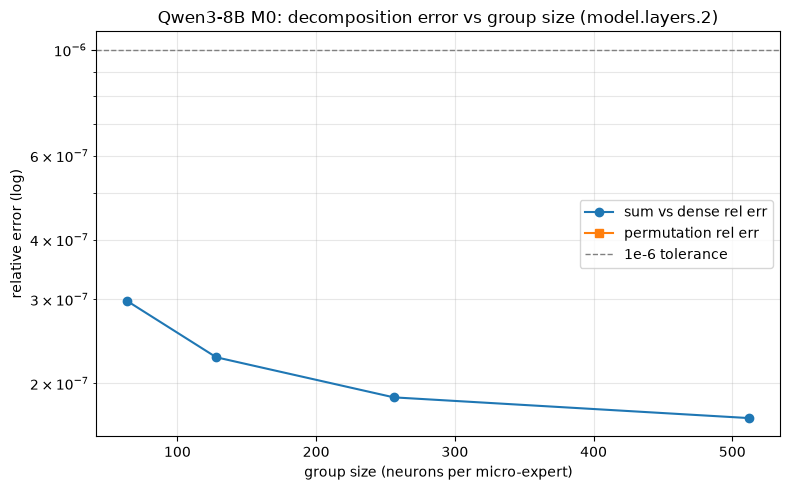

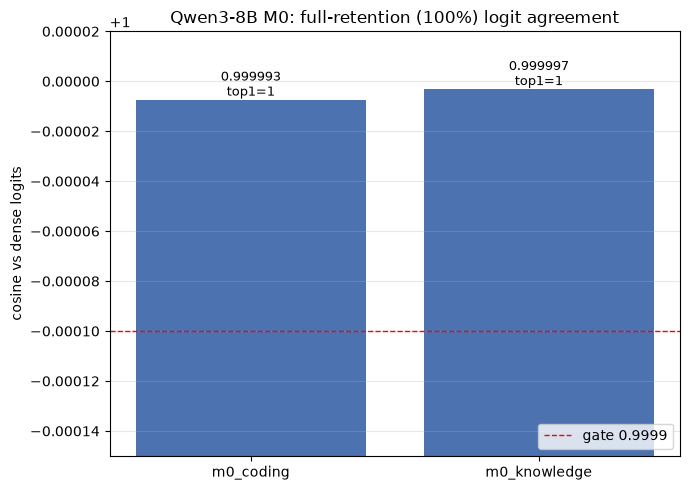

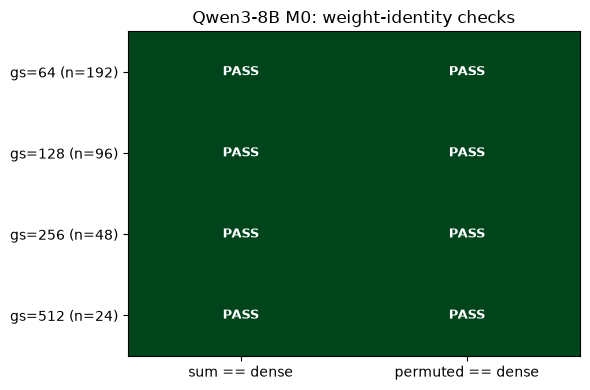

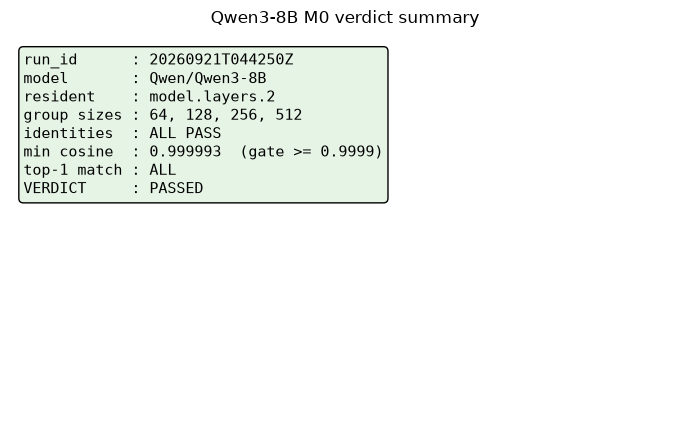

saved: E:\Project\SliceWeave\Qwen3-8B_Results\results\m0_exactness\plots\m0_relerr_vs_group_size.png  (55 KB)
saved: E:\Project\SliceWeave\Qwen3-8B_Results\results\m0_exactness\plots\m0_full_retention_cosine.png  (41 KB)
saved: E:\Project\SliceWeave\Qwen3-8B_Results\results\m0_exactness\plots\m0_identity_checks.png  (35 KB)
saved: E:\Project\SliceWeave\Qwen3-8B_Results\results\m0_exactness\plots\m0_verdict_summary.png  (44 KB)


In [2]:
# M0 plots — regenerate ALL FOUR from the M0 evidence on disk (CSV + verdict JSON).
# Reads the CSV fresh so this cell is deterministic and re-runnable; never touches
# the model. Mirrors the 4B study convention: plots live under m0_exactness/plots/.
import csv as _csv, json as _json
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

m0_csv = RESULTS / 'm0_exactness' / 'csv' / 'exactness_report.csv'
with open(m0_csv, encoding='utf-8') as f:
    m0_rows = list(_csv.DictReader(f))

verdict_paths = sorted((RESULTS / 'm0_exactness').glob('m0_verdict_*.json'))
m0_verdict = _json.loads(verdict_paths[-1].read_text(encoding='utf-8')) if verdict_paths else {}

weight_rows = [r for r in m0_rows if r['check_kind'] == 'weight_identity']
logit_rows  = [r for r in m0_rows if r['check_kind'] == 'full_retention_logits']

plot_dir = RESULTS / 'm0_exactness' / 'plots'
plot_dir.mkdir(parents=True, exist_ok=True)
_tag = MODEL_ID.split('/')[-1]

def _truthy(v):
    return str(v).strip().lower() == 'true'

# 1) m0_relerr_vs_group_size.png — decomposition fidelity per granularity
gs = [int(r['group_size']) for r in weight_rows]
err_sum = [float(r['rel_err_sum']) for r in weight_rows]
err_perm = [float(r['rel_err_perm']) for r in weight_rows]
figA, axA = plt.subplots(figsize=(8, 5))
axA.semilogy(gs, err_sum, marker='o', label='sum vs dense rel err')
axA.semilogy(gs, err_perm, marker='s', label='permutation rel err')
axA.axhline(1e-6, ls='--', c='gray', lw=1, label='1e-6 tolerance')
axA.set_xlabel('group size (neurons per micro-expert)')
axA.set_ylabel('relative error (log)')
axA.set_title(f'{_tag} M0: decomposition error vs group size ({weight_rows[0]["layer"]})')
axA.legend(); axA.grid(alpha=0.3, which='both')
figA.tight_layout()
pA = plot_dir / 'm0_relerr_vs_group_size.png'
figA.savefig(pA, dpi=150)

# 2) m0_full_retention_cosine.png — full-retention logit agreement
labels = [r['prompt_id'] for r in logit_rows]
cos = [float(r['full_retention_cosine']) for r in logit_rows]
t1  = [int(r['full_retention_top1_match']) for r in logit_rows]
figB, axB = plt.subplots(figsize=(7, 5))
bars = axB.bar(labels, cos, color='#4c72b0')
for rect, c, t in zip(bars, cos, t1):
    axB.text(rect.get_x() + rect.get_width()/2, c, f'{c:.6f}\ntop1={t}',
             ha='center', va='bottom', fontsize=9)
axB.axhline(0.9999, ls='--', c='red', lw=1, label='gate 0.9999')
axB.set_ylim(min(0.99985, min(cos) - 5e-5), 1.00002)
axB.set_ylabel('cosine vs dense logits')
axB.set_title(f'{_tag} M0: full-retention (100%) logit agreement')
axB.legend(loc='lower right'); axB.grid(alpha=0.3, axis='y')
figB.tight_layout()
pB = plot_dir / 'm0_full_retention_cosine.png'
figB.savefig(pB, dpi=150)

# 3) m0_identity_checks.png — identity matrix per group size
figC, axC = plt.subplots(figsize=(6, 4))
grid = np.array([[ _truthy(r['sum_equals_dense']), _truthy(r['permuted_equals_dense']) ]
                 for r in weight_rows], dtype=float)
axC.imshow(grid, cmap='Greens', vmin=0, vmax=1, aspect='auto')
axC.set_xticks([0, 1], ['sum == dense', 'permuted == dense'])
axC.set_yticks(range(len(weight_rows)),
               [f"gs={r['group_size']} (n={r['n_experts']})" for r in weight_rows])
for i, r in enumerate(weight_rows):
    for j in range(2):
        axC.text(j, i, 'PASS' if grid[i, j] else 'FAIL', ha='center', va='center',
                 color='white' if grid[i, j] else 'red', fontweight='bold', fontsize=9)
axC.set_title(f'{_tag} M0: weight-identity checks')
figC.tight_layout()
pC = plot_dir / 'm0_identity_checks.png'
figC.savefig(pC, dpi=150)

# 4) m0_verdict_summary.png — headline numbers from the verdict JSON
passed = bool(m0_verdict.get('passed', False))
all_cos = [float(r['full_retention_cosine']) for r in logit_rows if r['full_retention_cosine']]
min_cos = min(all_cos) if all_cos else float('nan')
figD, axD = plt.subplots(figsize=(7, 4.5))
axD.axis('off')
lines = [
    f"run_id      : {m0_verdict.get('run_id', RUN_ID)}",
    f"model       : {MODEL_ID}",
    f"resident    : {weight_rows[0]['layer'] if weight_rows else '?'}",
    f"group sizes : {', '.join(str(g) for g in gs)}",
    f"identities  : {'ALL PASS' if all(_truthy(r['sum_equals_dense']) and _truthy(r['permuted_equals_dense']) for r in weight_rows) else 'FAIL'}",
    f"min cosine  : {min_cos:.6f}  (gate >= 0.9999)",
    f"top-1 match : {'ALL' if all(int(r['full_retention_top1_match']) == 1 for r in logit_rows) else 'MISMATCH'}",
    f"VERDICT     : {'PASSED' if passed else 'FAILED'}",
]
axD.text(0.02, 0.95, '\n'.join(lines), family='monospace', fontsize=11,
         va='top', transform=axD.transAxes,
         bbox=dict(boxstyle='round', facecolor='#e6f4e6' if passed else '#fbe6e6'))
axD.set_title(f'{_tag} M0 verdict summary')
figD.tight_layout()
pD = plot_dir / 'm0_verdict_summary.png'
figD.savefig(pD, dpi=150)

plt.show(figA)
for p in (pA, pB, pC, pD):
    print(f"saved: {p}  ({p.stat().st_size/1024:.0f} KB)")


## M1 and beyond — separate per-milestone notebooks

M1 lives in `notebooks/oracle_milestone1.ipynb` (set `MODEL_KEY = 'qwen3_8b'`
in its config cell — it now supports the 8B bundle). This workbench stays
M0-only: setup, provenance, pinned load, exactness gate. One notebook per
milestone, matching the 4B study layout.
